In [1]:
from datasets import load_dataset
import gensim.models
from collections import Counter
import matplotlib.pyplot as plt

In [2]:
ds = load_dataset("wikimedia/wikipedia", "20231101.uk")

In [3]:
texts = []
for key in ds.values():
      print(key)
      for i, item in enumerate(key):
            texts.append(item["text"].split())
            if i == 10000:
                  break
      break


Dataset({
    features: ['id', 'url', 'title', 'text'],
    num_rows: 1294720
})


In [4]:
model = gensim.models.Word2Vec(sentences=texts)

In [6]:
model.wv.most_similar(positive=["система"], topn=5)

[('система,', 0.8381373882293701),
 ('структура', 0.8229484558105469),
 ('програма', 0.795380711555481),
 ('економіка', 0.7924943566322327),
 ('мережа', 0.7711902856826782)]

In [7]:
sentences = []
symbol = ["!", "?", "\n"]
list_sym = "абвгґдеєжзиіїйклмнопрстуфхцчшщьюя'-"

for item in ds["train"]:
      article = item["text"].lower()
      for sumb in symbol:
            article = article.replace(sumb, ".")
      parts = article.split(".")
      for sent in parts:
            sent = sent.replace("\u0301", "").replace("\u2019", "'").replace("\u02bc", "'")
            clean = ""

            for sm in sent:
                  if sm in list_sym:
                        clean += sm
                  else:
                        clean += " "
            words = clean.split()
            words = [word.strip("'-") for word in words]
            words = [word for word in words if len(word)>=3]
            
            if len(words) >= 5:
                  sentences.append(words)
      if len(sentences) >= 300000:
            break

sentences = sentences[:300000]

In [8]:
print(sentences[:5])

[['землепис', 'від', 'опис', 'землі', 'земля', 'писати', 'описувати', 'система', 'наук', 'вивчає', 'географічну', 'оболонку', 'землі', 'епігеосферу', 'просторову', 'природну', 'соціально-економічну', 'різноманітність', 'господарство', 'населення', 'планети', 'окремих', 'регіонів', 'країн', 'також', "зв'язки", 'між', 'природним', 'середовищем', 'діяльністю', 'людини'], ['сучасному', 'розумінні', 'поняття', 'географія', 'заміщено', 'поняттям', 'географічні', 'науки'], ['уперше', 'термін', 'географія', 'був', 'запропонований', 'давньогрецьким', 'географом', 'ератосфеном'], ['основне', 'завдання', 'сучасної', 'географії', 'полягає', 'вивченні', 'законів', 'закономірностей', 'розміщення', 'взаємодії', 'компонентів', 'географічного', 'середовища', 'їхніх', 'поєднань', 'різних', 'рівнях'], ['складність', "об'єкта", 'дослідження', 'широта', 'предметної', 'області', 'зумовили', 'диференціацію', 'єдиної', 'географії', 'низку', 'спеціалізованих', 'галузевих', 'наукових', 'дисциплін', 'які', 'утво

In [9]:
len(sentences)

300000

In [10]:
count = Counter()

for sent in sentences:
      count.update(sent)
len(count)      

286273

In [11]:
top20 = count.most_common(20)
top20

[('року', 24698),
 ('від', 16448),
 ('його', 12893),
 ('для', 12683),
 ('україни', 11606),
 ('про', 11483),
 ('під', 9669),
 ('також', 9445),
 ('було', 8861),
 ('році', 8633),
 ('був', 7650),
 ('він', 7425),
 ('після', 7254),
 ('району', 7127),
 ('які', 6956),
 ('або', 6604),
 ('час', 5988),
 ('території', 5875),
 ('але', 5847),
 ('між', 5724)]

In [12]:
word_top = [pair[0] for pair in top20]
count_top = [pair[1] for pair in top20]

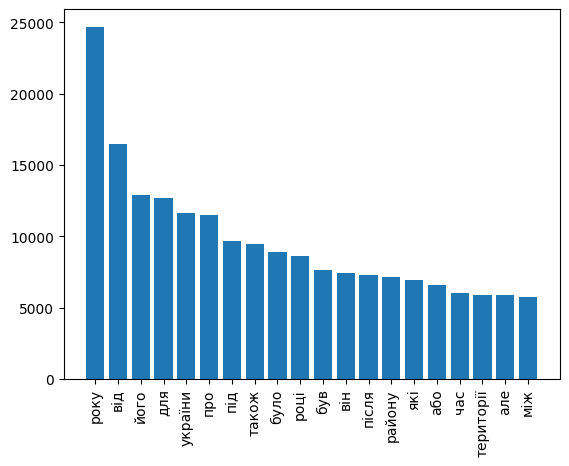

In [13]:
plt.bar(word_top, count_top)
plt.xticks(rotation=90)
plt.show()